# colouring (assign_colors)

here are some code blocks on color assigment that I used to understand how it works in matplotlib and use in SynViser later on.

## setup

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, PathPatch
from matplotlib.path import Path

Thats our function from `drawing_studies.ipynb`:

In [ ]:
def make_ribbon(top_chr_span, bot_chr_span, y_top, y_bot, color):
    xa1, xa2 = top_chr_span
    xb1, xb2 = bot_chr_span
    ym = (y_top + y_bot) / 2
    verts = [(xa1, y_top), (xa1, ym), (xb1, ym), (xb1, y_bot), (xb2, y_bot), (xb2, ym), (xa2, ym), (xa2, y_top), (xa1, y_top)]
    codes = [Path.MOVETO, Path.CURVE4, Path.CURVE4, Path.CURVE4, Path.LINETO, Path.CURVE4, Path.CURVE4, Path.CURVE4, Path.CLOSEPOLY]
    return PathPatch(Path(verts, codes), facecolor=color, alpha=0.7, edgecolor="none")

def foot(cx):
    return (cx - 0.03, cx + 0.03)

Some pre-defined parameters/variables/functions to save some space later on. Most important here is bar(), bc it defines appearance of chr, and we will be mainly playing around with it.

In [ ]:
TOP = 2.0
MID = 1.0
BOT = 0.0
H = 0.12 # just for convinience as its easier to understand what where belongs

def bar(ax, x, y, color="gray"):
    ax.add_patch(Rectangle((x - 0.08, y), 0.16, H, facecolor=color))

def ribbon(ax, xu, xl, yu, yl, color="gray"):
    ax.add_patch(make_ribbon(foot(xu), foot(xl), yu, yl + H, color))

def frame(ax):
    ax.set_xlim(0, 1)
    ax.set_ylim(-0.2, 2.4)
    ax.axis("off")

## 1 manual coloring
So same as in `drawing_studies` notebook we can just change color of chr or ribbon directly with `color/facelor="some_colour"`.

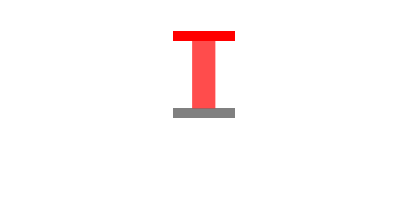

In [ ]:
fig1, ax1 = plt.subplots(figsize=(5, 2.6))
bar(ax1, 0.5, TOP, "red") # HERE
bar(ax1, 0.5, MID)
ribbon(ax1, 0.5, 0.5, TOP, MID, "red") # HERE
frame(ax1)
fig1

## 2colour from a dict

In order to deal with many genes/loci its easier to write them as dict:

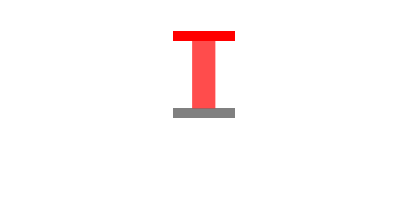

In [ ]:
focal = {"A1": "red"}

fig2, ax2 = plt.subplots(figsize=(5, 2.6))
bar(ax2, 0.5, TOP, focal["A1"])
bar(ax2, 0.5, MID)
ribbon(ax2, 0.5, 0.5, TOP, MID, focal["A1"])
frame(ax2)
fig2

## 3 two chromosomes

then you can just keep expanding that dict

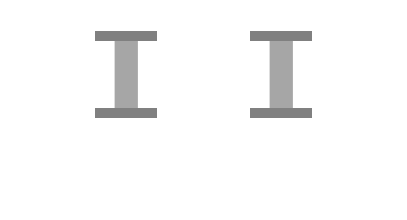

In [ ]:
fig3_1, ax3_1 = plt.subplots(figsize=(5, 2.6))
bar(ax3_1, 0.3, TOP)
bar(ax3_1, 0.7, TOP)
bar(ax3_1, 0.3, MID)
bar(ax3_1, 0.7, MID)
ribbon(ax3_1, 0.3, 0.3, TOP, MID)
ribbon(ax3_1, 0.7, 0.7, TOP, MID)
frame(ax3_1)
fig3_1

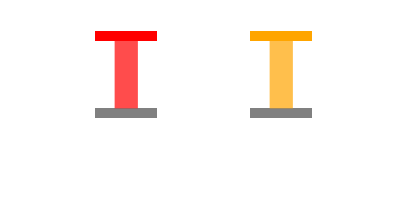

In [ ]:
two = {"A1": "red", "A2": "orange"}

fig3_2, ax3_2 = plt.subplots(figsize=(5, 2.6))
bar(ax3_2, 0.3, TOP, two["A1"]) # <dict
bar(ax3_2, 0.7, TOP, two["A2"]) # <dict
bar(ax3_2, 0.3, MID)
bar(ax3_2, 0.7, MID)
ribbon(ax3_2, 0.3, 0.3, TOP, MID, two["A1"]) # <dict
ribbon(ax3_2, 0.7, 0.7, TOP, MID, two["A2"]) # <dict
frame(ax3_2)
fig3_2

## 4 add a third species - B has no colour

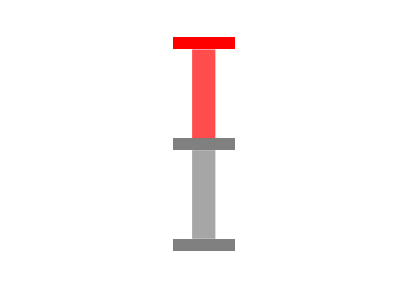

In [ ]:
fig4, ax4 = plt.subplots(figsize=(5, 3.4))
bar(ax4, 0.5, TOP, focal["A1"])
bar(ax4, 0.5, MID)
bar(ax4, 0.5, BOT)
ribbon(ax4, 0.5, 0.5, TOP, MID, focal["A1"])
ribbon(ax4, 0.5, 0.5, MID, BOT)
frame(ax4)
fig4

Or we can color them

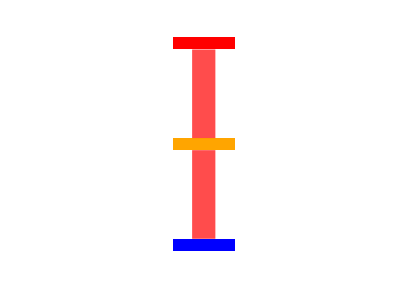

In [ ]:
fig4_1, ax4_1 = plt.subplots(figsize=(5, 3.4))
bar(ax4_1, 0.5, TOP, focal["A1"])
bar(ax4_1, 0.5, MID, "orange")
bar(ax4_1, 0.5, BOT, "blue")
ribbon(ax4_1, 0.5, 0.5, TOP, MID, focal["A1"])
ribbon(ax4_1, 0.5, 0.5, MID, BOT, focal["A1"])
frame(ax4_1)
fig4_1

## 5 remember B1's colour

Then we can introduce some means to store colour.

In [ ]:
known = {}
known["B1"] = focal["A1"]

known

## 6 now B to C reads known

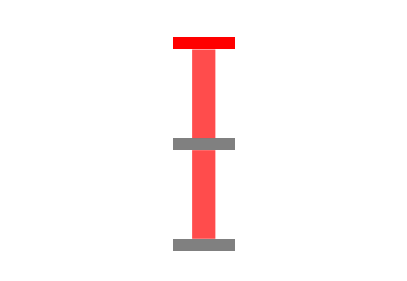

In [ ]:
fig6, ax6 = plt.subplots(figsize=(5, 3.4))
bar(ax6, 0.5, TOP, focal["A1"])
bar(ax6, 0.5, MID)
bar(ax6, 0.5, BOT)
ribbon(ax6, 0.5, 0.5, TOP, MID, focal["A1"])
ribbon(ax6, 0.5, 0.5, MID, BOT, known["B1"])
frame(ax6)
fig6

## 7 an orphan stays grey

And then we can emphasise ribbons with N/A by drawing them gray.

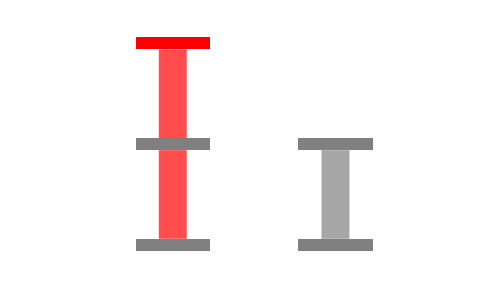

In [ ]:
fig7, ax7 = plt.subplots(figsize=(6, 3.4))
bar(ax7, 0.35, TOP, focal["A1"])
bar(ax7, 0.35, MID)
bar(ax7, 0.35, BOT)
ribbon(ax7, 0.35, 0.35, TOP, MID, focal["A1"])
ribbon(ax7, 0.35, 0.35, MID, BOT, known["B1"])
bar(ax7, 0.7, MID)
bar(ax7, 0.7, BOT)
ribbon(ax7, 0.7, 0.7, MID, BOT, known.get("B9", "grey"))
frame(ax7)
fig7

## 8 same thing as a loop

Then to wrap up, we just write all that logic in the loop, this is how we get `assign_colors()` (name might differ) in SynViser.

In [ ]:
focal_colors = {"A1": "red", "A2": "blue"}
links = {("A", "B"): [("A1", "B1")], ("B", "C"): [("B1", "C1"), ("B9", "C9")]}

seen = {}
for a, b in links[("A", "B")]:
    seen[b] = focal_colors.get(a, "gray")
for b, c in links[("B", "C")]:
    seen[c] = seen.get(b, "gray")

seen